# 7장. 그래프로 데이터의 이야기를 보여주기

이 노트북은 `book/chapters/ch07_visualization.md` 강의안을 초보자가 그대로 따라 하며 이해할 수 있도록 구성한 실습 자료입니다.

이번 장의 핵심은 그래프를 많이 그리는 것이 아니라, **분석 질문에 맞는 그래프를 고르고, 그래프가 보여주는 것과 보여주지 않는 것을 구분하는 것**입니다.


## 0. 이 노트북 사용 방법

아래 셀을 위에서부터 차례대로 실행하세요.

- 이 노트북은 5장에서 만든 `data/processed/*_clean.csv` 파일을 사용합니다.
- 전처리 파일이 없다면 먼저 `python scripts/preprocess_data.py`를 실행하세요.
- 그래프 파일은 `reports/figures/` 폴더에 저장합니다.
- 그래프 해석에서는 관찰과 원인 가설을 반드시 구분합니다.


## 1. 시각화는 분석 질문에서 시작된다

좋은 시각화는 그래프 종류를 많이 아는 데서 시작하지 않습니다. 먼저 어떤 질문에 답하려는지 정해야 합니다.

| 분석 목적 | 적합한 그래프 | 예시 질문 |
|---|---|---|
| 범주별 크기 비교 | 막대그래프 | 카테고리별 매출은 어떻게 다른가? |
| 시간 흐름 확인 | 선 그래프 | 월별 매출은 어떻게 변하는가? |
| 값의 분포 확인 | 히스토그램 | 상품 가격은 어떤 범위에 몰려 있는가? |
| 두 변수 관계 확인 | 산점도 | 가격과 판매 수량은 관계가 있는가? |
| 상위 항목 비교 | 가로 막대그래프 | 구매 금액 상위 고객은 누구인가? |
| 비율 비교 | 막대그래프 또는 파이 차트 | 주문 상태별 비중은 어떻게 되는가? |


## 2. 이번 장에서 만들 그래프

이번 장에서는 6장 EDA에서 만든 질문을 그래프로 표현합니다.

| 시각화 질문 | 사용할 데이터 | 그래프 |
|---|---|---|
| 카테고리별 매출은 어떻게 다른가? | `category_sales` | 막대그래프 |
| 월별 매출은 어떻게 변하는가? | `monthly_sales` | 선 그래프 |
| 상품 가격은 어떤 구간에 몰려 있는가? | `products` | 히스토그램 |
| 상품 가격과 판매 수량은 관계가 있는가? | `product_sales` | 산점도 |
| 구매 금액 상위 고객은 누구인가? | `customer_sales` | 가로 막대그래프 |
| 주문 상태별 주문 수는 어떻게 다른가? | `orders` | 막대그래프 |


## 3. 패키지와 경로 설정

노트북이 `notebooks/` 폴더 안에서 실행되는 경우와 프로젝트 루트에서 실행되는 경우를 모두 고려해 경로를 설정합니다.


In [6]:
from pathlib import Path
import sys

import pandas as pd
import matplotlib.pyplot as plt

CURRENT_DIR = Path.cwd()

#if CURRENT_DIR.name == 'notebooks':
if CURRENT_DIR.name == 'chapter07':  #내 과제에서는 llm-data-analysis-course\practice\chapter05 폴더 안에서 실행
    PROJECT_ROOT = CURRENT_DIR.parent.parent # 2단계 상위 폴더로 이동하여 프로젝트 루트 경로를 설정
else:
    PROJECT_ROOT = CURRENT_DIR

PROCESSED_DIR = PROJECT_ROOT / 'data' / 'processed'
REPORT_DIR = PROJECT_ROOT / 'reports'
FIGURE_DIR = REPORT_DIR / 'figures'

REPORT_DIR.mkdir(exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print('현재 실행 위치:', CURRENT_DIR)
print('프로젝트 루트:', PROJECT_ROOT)
print('전처리 데이터 폴더:', PROCESSED_DIR)
print('그래프 저장 폴더:', FIGURE_DIR)


현재 실행 위치: c:\dev\git\llm-data-analysis-course\practice\chapter07
프로젝트 루트: c:\dev\git\llm-data-analysis-course
전처리 데이터 폴더: c:\dev\git\llm-data-analysis-course\data\processed
그래프 저장 폴더: c:\dev\git\llm-data-analysis-course\reports\figures


## 4. 한글 폰트 설정

matplotlib에서 한글 제목이나 축 이름을 사용하면 글자가 깨질 수 있습니다. Windows 환경에서는 보통 `Malgun Gothic`을 사용합니다. Mac은 `AppleGothic`, Linux는 `NanumGothic`을 사용할 수 있습니다.


In [7]:
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

print('matplotlib 한글 폰트 설정 완료')


matplotlib 한글 폰트 설정 완료


## 5. 전처리 데이터 불러오기

7장은 5장에서 저장한 전처리 데이터를 사용합니다. 파일이 없다면 터미널에서 `python scripts/preprocess_data.py`를 먼저 실행하세요.


In [8]:
required_files = [
    PROCESSED_DIR / 'customers_clean.csv',
    PROCESSED_DIR / 'products_clean.csv',
    PROCESSED_DIR / 'orders_clean.csv',
    PROCESSED_DIR / 'order_items_clean.csv',
]

missing_files = [path for path in required_files if not path.exists()]
if missing_files:
    for path in missing_files:
        print('누락 파일:', path)
    raise FileNotFoundError('전처리 파일이 없습니다. 먼저 python scripts/preprocess_data.py 를 실행하세요.')

customers = pd.read_csv(PROCESSED_DIR / 'customers_clean.csv')
products = pd.read_csv(PROCESSED_DIR / 'products_clean.csv')
orders = pd.read_csv(PROCESSED_DIR / 'orders_clean.csv')
order_items = pd.read_csv(PROCESSED_DIR / 'order_items_clean.csv')

print('전처리 데이터 불러오기 완료')


전처리 데이터 불러오기 완료


In [9]:
orders['order_date'] = pd.to_datetime(orders['order_date'], errors='coerce')

if 'order_month' not in orders.columns:
    orders['order_month'] = orders['order_date'].dt.to_period('M').astype(str)

if 'line_total' not in order_items.columns:
    order_items['line_total'] = order_items['quantity'] * order_items['unit_price']

print('customers:', customers.shape)
print('products:', products.shape)
print('orders:', orders.shape)
print('order_items:', order_items.shape)


customers: (150, 6)
products: (100, 4)
orders: (300, 7)
order_items: (764, 6)


## 6. 시각화를 위한 집계 데이터 만들기

그래프를 그리기 전에 필요한 집계표를 만듭니다. 대부분의 시각화는 원본 데이터를 바로 그리기보다, 질문에 맞게 요약한 표를 만든 뒤 그립니다.


In [10]:
sales_items = order_items.merge(
    products,
    on='product_id',
    how='left',
)

print('병합 전 order_items:', order_items.shape)
print('병합 후 sales_items:', sales_items.shape)
print('카테고리 누락:', sales_items['category'].isna().sum())

sales_items.head()


병합 전 order_items: (764, 6)
병합 후 sales_items: (764, 9)
카테고리 누락: 0


,order_item_id,order_id,product_id,quantity,unit_price,line_total,product_name,category,price
0,1,1,100,3,102000,306000,도서 상품 100,도서,102000
1,2,1,87,5,25000,125000,도서 상품 087,도서,25000
2,3,1,7,3,142000,426000,도서 상품 007,도서,142000
3,4,1,9,3,193000,579000,스포츠 상품 009,스포츠,193000
4,5,2,72,4,189000,756000,뷰티 상품 072,뷰티,189000


In [11]:
category_sales = (
    sales_items
    .groupby('category', as_index=False)
    .agg(
        total_quantity=('quantity', 'sum'),
        total_sales=('line_total', 'sum'),
    )
    .sort_values('total_sales', ascending=False)
)

category_sales['sales_ratio'] = (
    category_sales['total_sales'] / category_sales['total_sales'].sum() * 100
).round(2)

category_sales


,category,total_quantity,total_sales,sales_ratio
3,스포츠,468,50174000,19.63
1,뷰티,376,47551000,18.60
5,전자기기,401,41003000,16.04
2,생활용품,390,34839000,13.63
4,식품,240,33597000,13.14
0,도서,238,24645000,9.64
6,패션,220,23801000,9.31


In [12]:
order_sales = order_items.merge(
    orders,
    on='order_id',
    how='left',
)

order_sales['order_date'] = pd.to_datetime(order_sales['order_date'], errors='coerce')
order_sales['order_month'] = order_sales['order_date'].dt.to_period('M').astype(str)

monthly_sales = (
    order_sales
    .groupby('order_month', as_index=False)
    .agg(
        total_sales=('line_total', 'sum'),
        order_count=('order_id', 'nunique'),
    )
    .sort_values('order_month')
)

monthly_sales


,order_month,total_sales,order_count
0,2025-09,4950000,9
1,2025-10,25481000,27
2,2025-11,18572000,22
3,2025-12,30112000,33
4,2026-01,29110000,29
5,2026-02,14289000,17
6,2026-03,25161000,35
7,2026-04,24160000,27
8,2026-05,25061000,28
9,2026-06,18316000,25


In [13]:
product_sales = (
    sales_items
    .groupby(['product_id', 'product_name', 'category', 'price'], as_index=False)
    .agg(
        total_quantity=('quantity', 'sum'),
        total_sales=('line_total', 'sum'),
    )
    .sort_values('total_sales', ascending=False)
)

product_sales.head()


,product_id,product_name,category,price,total_quantity,total_sales
57,58,식품 상품 058,식품,197000,59,11623000
98,99,뷰티 상품 099,뷰티,200000,38,7600000
40,41,스포츠 상품 041,스포츠,163000,42,6846000
71,72,뷰티 상품 072,뷰티,189000,36,6804000
70,71,전자기기 상품 071,전자기기,161000,41,6601000


In [14]:
customer_sales_base = order_sales.merge(
    customers,
    on='customer_id',
    how='left',
)

group_columns = ['customer_id', 'city']
if 'name' in customer_sales_base.columns:
    group_columns = ['customer_id', 'name', 'city']

customer_sales = (
    customer_sales_base
    .groupby(group_columns, as_index=False)
    .agg(
        order_count=('order_id', 'nunique'),
        total_sales=('line_total', 'sum'),
    )
    .sort_values('total_sales', ascending=False)
)

customer_sales['avg_order_value'] = (
    customer_sales['total_sales'] / customer_sales['order_count']
).round(0)

customer_sales.head()


,customer_id,name,city,order_count,total_sales,avg_order_value
79,102,이진호,고양,5,5977000,1195400.0
93,117,김지원,성남,6,5552000,925333.0
67,83,전은경,수원,5,4951000,990200.0
118,142,하서연,서울,3,4862000,1620667.0
34,40,박예준,서울,5,4857000,971400.0


In [15]:
order_status = orders['order_status'].value_counts(dropna=False).reset_index()
order_status.columns = ['order_status', 'order_count']
order_status


,order_status,order_count
0,completed,184
1,cancelled,64
2,refunded,52


## 7. 카테고리별 매출 막대그래프

카테고리별 매출은 범주별 크기 비교이므로 막대그래프가 적합합니다. 그래프는 화면에 표시하고 동시에 PNG 파일로 저장합니다.


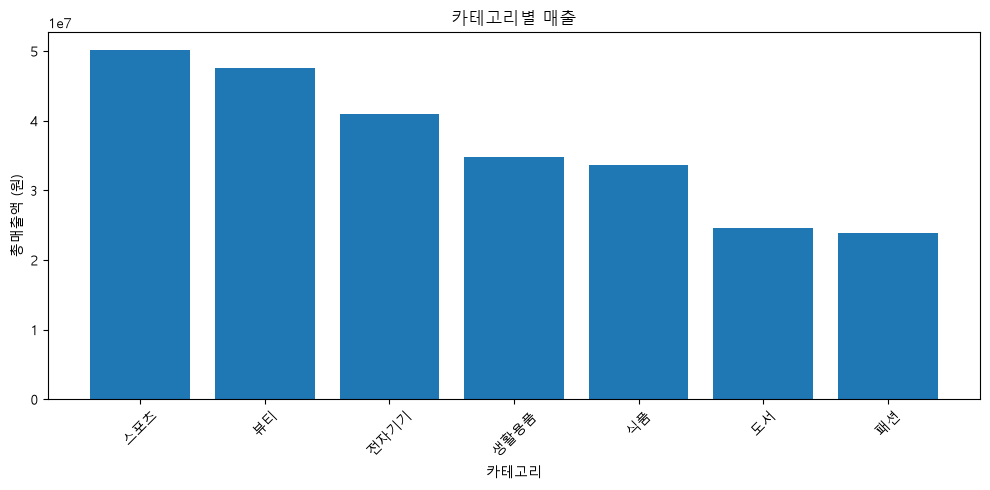

In [16]:
plt.figure(figsize=(10, 5))
plt.bar(category_sales['category'], category_sales['total_sales'])
plt.title('카테고리별 매출')
plt.xlabel('카테고리')
plt.ylabel('총매출액 (원)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'ch07_category_sales_bar.png', dpi=150, bbox_inches='tight')
plt.show()


해석 예시:

> 관찰: 카테고리별 매출 크기가 서로 다르게 나타납니다.
> 가설: 매출 차이는 판매 수량 또는 평균 단가 차이에서 비롯되었을 수 있습니다.
> 추가 분석: 카테고리별 판매 수량과 평균 단가를 함께 확인해야 합니다.


## 8. 월별 매출 선 그래프

월별 매출은 시간 흐름을 보는 문제이므로 선 그래프가 적합합니다. x축 순서가 월 순서대로 정렬되어 있어야 합니다.


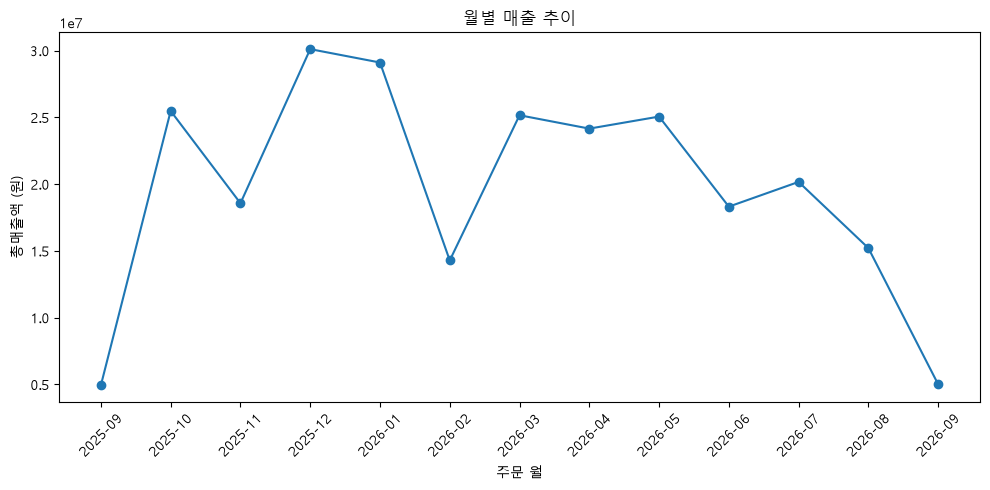

In [17]:
plt.figure(figsize=(10, 5))
plt.plot(monthly_sales['order_month'], monthly_sales['total_sales'], marker='o')
plt.title('월별 매출 추이')
plt.xlabel('주문 월')
plt.ylabel('총매출액 (원)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'ch07_monthly_sales_line.png', dpi=150, bbox_inches='tight')
plt.show()


월별 매출이 증가하거나 감소해도 그 원인을 바로 단정하면 안 됩니다. 주문 수, 평균 주문 금액, 프로모션 여부, 특정 카테고리 매출 변화를 추가로 확인해야 합니다.


## 9. 상품 가격 분포 히스토그램

히스토그램은 숫자형 데이터가 어느 구간에 많이 몰려 있는지 보여줍니다. 상품 가격 분포를 보면 저가/중가/고가 상품이 어떻게 분포하는지 확인할 수 있습니다.


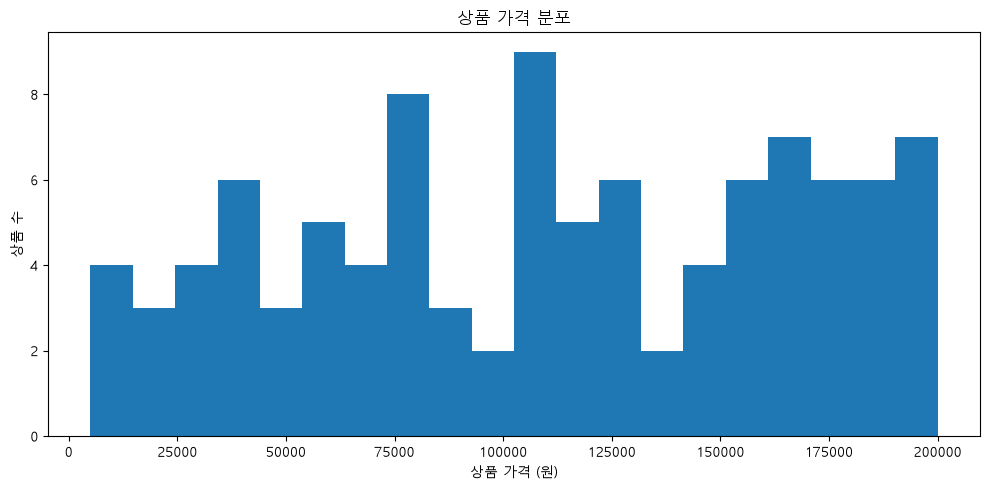

In [18]:
plt.figure(figsize=(10, 5))
plt.hist(products['price'], bins=20)
plt.title('상품 가격 분포')
plt.xlabel('상품 가격 (원)')
plt.ylabel('상품 수')
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'ch07_product_price_hist.png', dpi=150, bbox_inches='tight')
plt.show()


## 10. 상품 가격과 판매 수량 산점도

산점도는 두 숫자형 변수의 관계를 탐색할 때 사용합니다. 여기서는 상품 가격과 총 판매 수량 사이의 관계를 확인합니다. 산점도만으로 원인 관계를 단정해서는 안 됩니다.


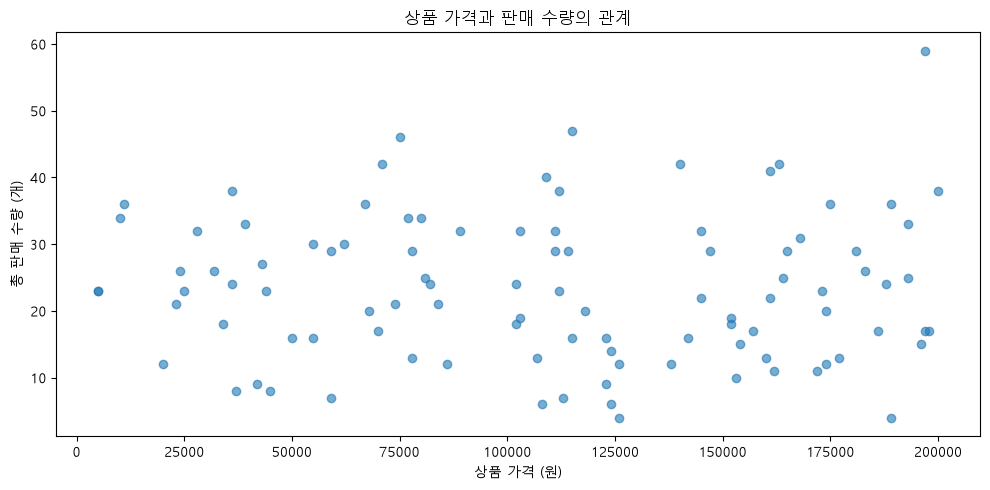

In [19]:
plt.figure(figsize=(10, 5))
plt.scatter(product_sales['price'], product_sales['total_quantity'], alpha=0.6)
plt.title('상품 가격과 판매 수량의 관계')
plt.xlabel('상품 가격 (원)')
plt.ylabel('총 판매 수량 (개)')
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'ch07_price_quantity_scatter.png', dpi=150, bbox_inches='tight')
plt.show()


## 11. 구매 금액 상위 고객 가로 막대그래프

상위 항목을 비교할 때는 가로 막대그래프가 읽기 좋습니다. 고객명은 개인정보가 될 수 있으므로 보고서에서는 익명화 라벨을 사용하는 것이 좋습니다.


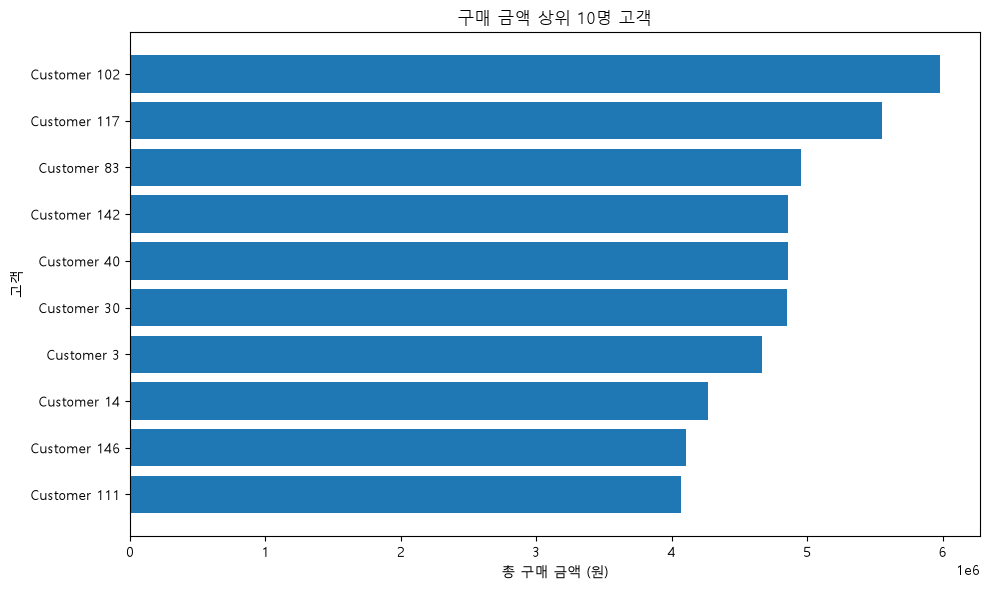

In [20]:
top_customers = customer_sales.head(10).copy()
top_customers['customer_label'] = 'Customer ' + top_customers['customer_id'].astype(str)
top_customers = top_customers.sort_values('total_sales')

plt.figure(figsize=(10, 6))
plt.barh(top_customers['customer_label'], top_customers['total_sales'])
plt.title('구매 금액 상위 10명 고객')
plt.xlabel('총 구매 금액 (원)')
plt.ylabel('고객')
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'ch07_top_customers_barh.png', dpi=150, bbox_inches='tight')
plt.show()


고객별 구매 금액 상위 그래프는 우수 고객 후보를 확인하는 데 유용합니다. 하지만 한 번에 많이 구매한 고객과 여러 번 반복 구매한 고객은 구분해서 해석해야 합니다.


## 12. 주문 상태별 주문 수 막대그래프

주문 상태별 주문 수는 완료, 취소, 환불 등 주문 상태의 분포를 확인하는 데 사용합니다.


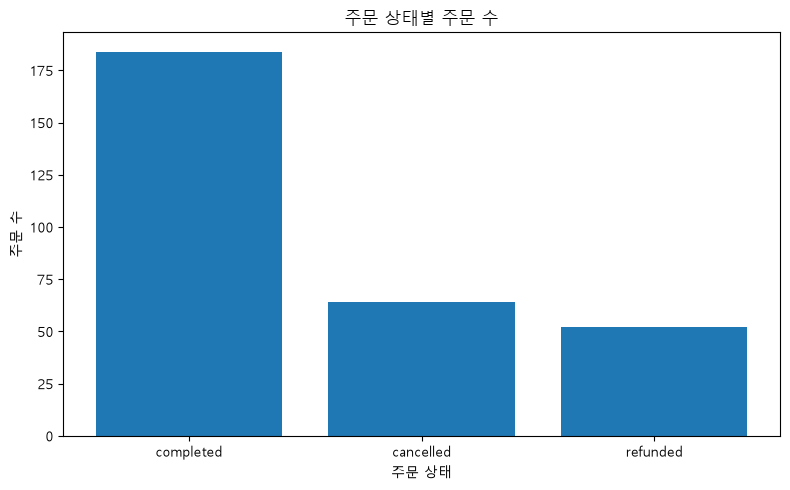

In [21]:
plt.figure(figsize=(8, 5))
plt.bar(order_status['order_status'], order_status['order_count'])
plt.title('주문 상태별 주문 수')
plt.xlabel('주문 상태')
plt.ylabel('주문 수')
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'ch07_order_status_bar.png', dpi=150, bbox_inches='tight')
plt.show()


## 13. 저장된 그래프 확인하기

생성된 그래프 파일을 확인합니다. 보고서나 발표 자료에 사용할 수 있도록 `reports/figures` 폴더에 저장했습니다.


In [22]:
list(FIGURE_DIR.glob('ch07_*.png'))


[WindowsPath('c:/dev/git/llm-data-analysis-course/reports/figures/ch07_category_sales_bar.png'),
 WindowsPath('c:/dev/git/llm-data-analysis-course/reports/figures/ch07_homework01.png'),
 WindowsPath('c:/dev/git/llm-data-analysis-course/reports/figures/ch07_homework04.png'),
 WindowsPath('c:/dev/git/llm-data-analysis-course/reports/figures/ch07_monthly_sales_line.png'),
 WindowsPath('c:/dev/git/llm-data-analysis-course/reports/figures/ch07_order_status_bar.png'),
 WindowsPath('c:/dev/git/llm-data-analysis-course/reports/figures/ch07_price_quantity_scatter.png'),
 WindowsPath('c:/dev/git/llm-data-analysis-course/reports/figures/ch07_product_price_hist.png'),
 WindowsPath('c:/dev/git/llm-data-analysis-course/reports/figures/ch07_top_customers_barh.png')]

## 14. 시각화 요약표 만들기

각 그래프의 목적과 해석 포인트를 표로 정리하면 이후 보고서 작성이 쉬워집니다.


In [23]:
visualization_summary = pd.DataFrame({
    'chart': [
        '카테고리별 매출 막대그래프',
        '월별 매출 선 그래프',
        '상품 가격 분포 히스토그램',
        '상품 가격과 판매 수량 산점도',
        '구매 금액 상위 고객 가로 막대그래프',
        '주문 상태별 주문 수 막대그래프',
    ],
    'question': [
        '카테고리별 매출은 어떻게 다른가?',
        '월별 매출은 어떻게 변하는가?',
        '상품 가격은 어떤 구간에 몰려 있는가?',
        '상품 가격과 판매 수량은 관계가 있는가?',
        '구매 금액이 높은 고객은 누구인가?',
        '주문 상태별 주문 수는 어떻게 다른가?',
    ],
    'interpretation_point': [
        '매출 기여도가 높은 카테고리 확인',
        '시간에 따른 증가와 감소 흐름 확인',
        '상품 가격대의 분포와 이상값 후보 확인',
        '가격과 판매 수량의 관계 탐색',
        '우수 고객 후보 확인',
        '완료, 취소 등 주문 상태 분포 확인',
    ],
    'file_name': [
        'ch07_category_sales_bar.png',
        'ch07_monthly_sales_line.png',
        'ch07_product_price_hist.png',
        'ch07_price_quantity_scatter.png',
        'ch07_top_customers_barh.png',
        'ch07_order_status_bar.png',
    ],
})

visualization_summary


,chart,question,interpretation_point,file_name
0,카테고리별 매출 막대그래프,카테고리별 매출은 어떻게 다른가?,매출 기여도가 높은 카테고리 확인,ch07_category_sales_bar.png
1,월별 매출 선 그래프,월별 매출은 어떻게 변하는가?,시간에 따른 증가와 감소 흐름 확인,ch07_monthly_sales_line.png
2,상품 가격 분포 히스토그램,상품 가격은 어떤 구간에 몰려 있는가?,상품 가격대의 분포와 이상값 후보 확인,ch07_product_price_hist.png
3,상품 가격과 판매 수량 산점도,상품 가격과 판매 수량은 관계가 있는가?,가격과 판매 수량의 관계 탐색,ch07_price_quantity_scatter.png
4,구매 금액 상위 고객 가로 막대그래프,구매 금액이 높은 고객은 누구인가?,우수 고객 후보 확인,ch07_top_customers_barh.png
5,주문 상태별 주문 수 막대그래프,주문 상태별 주문 수는 어떻게 다른가?,"완료, 취소 등 주문 상태 분포 확인",ch07_order_status_bar.png


## 15. 시각화 요약 보고서 저장하기

시각화 목적, 생성한 그래프 목록, 해석 포인트, 주의사항을 Markdown 보고서로 저장합니다.


In [24]:
summary_text = f'''# Chapter 7 데이터 시각화 요약 보고서

## 1. 시각화 목적

전처리 및 EDA 결과를 바탕으로 온라인 쇼핑몰 데이터의 주요 패턴을 그래프로 확인했습니다.

## 2. 생성한 그래프 목록

```text
{visualization_summary.to_string(index=False)}
```

## 3. 주요 해석 포인트

- 카테고리별 매출 그래프를 통해 매출 기여도가 높은 상품군을 확인할 수 있습니다.
- 월별 매출 선 그래프를 통해 시간에 따른 매출 흐름을 확인할 수 있습니다.
- 상품 가격 히스토그램을 통해 상품 가격대 분포를 확인할 수 있습니다.
- 가격과 판매 수량 산점도는 두 변수 사이의 관계를 탐색하는 데 사용합니다.
- 고객별 구매 금액 상위 그래프는 우수 고객 후보를 파악하는 데 유용합니다.
- 주문 상태별 주문 수 그래프는 완료, 취소 등 주문 상태의 분포를 확인하는 데 사용합니다.

## 4. 해석 시 주의사항

- 그래프는 데이터를 쉽게 보여주지만 원인을 자동으로 설명하지는 않습니다.
- 매출이 높은 이유는 판매 수량, 단가, 주문 수 등을 함께 확인해야 합니다.
- 고객명 등 개인정보가 포함될 수 있는 그래프는 익명화가 필요할 수 있습니다.
- 시각화 결과는 보고서에 넣기 전에 축, 제목, 단위가 명확한지 확인해야 합니다.

## 5. 다음 단계

다음 장에서는 지금까지 배운 데이터 불러오기, 전처리, EDA, 시각화를 종합하여 중간 실습 프로젝트를 수행합니다.
'''

summary_path = REPORT_DIR / 'ch07_visualization_summary.md'
summary_path.write_text(summary_text, encoding='utf-8')

print('시각화 요약 보고서 저장 완료:', summary_path)


시각화 요약 보고서 저장 완료: c:\dev\git\llm-data-analysis-course\reports\ch07_visualization_summary.md


## 16. 소스 모듈로 같은 시각화 실행하기

위에서 노트북으로 한 단계씩 실행한 시각화는 `src/visualization.py`에 함수로 정리되어 있습니다. 반복 실행하거나 프로젝트 코드로 관리하려면 소스 모듈을 사용하는 것이 좋습니다.


In [25]:
from src.visualization import (
    create_all_figures,
    create_visualization_summary,
    prepare_visualization_data,
    setup_korean_font,
)

setup_korean_font()
module_viz_data = prepare_visualization_data(PROCESSED_DIR)
module_viz_summary = create_visualization_summary()
module_viz_summary


,chart,question,interpretation_point,file_name
0,카테고리별 매출 막대그래프,카테고리별 매출은 어떻게 다른가?,매출 기여도가 높은 카테고리 확인,ch07_category_sales_bar.png
1,월별 매출 선 그래프,월별 매출은 어떻게 변하는가?,시간에 따른 증가와 감소 흐름 확인,ch07_monthly_sales_line.png
2,상품 가격 분포 히스토그램,상품 가격은 어떤 구간에 몰려 있는가?,상품 가격대의 분포와 이상값 후보 확인,ch07_product_price_hist.png
3,상품 가격과 판매 수량 산점도,상품 가격과 판매 수량은 관계가 있는가?,가격과 판매 수량의 관계 탐색,ch07_price_quantity_scatter.png
4,구매 금액 상위 고객 가로 막대그래프,구매 금액이 높은 고객은 누구인가?,우수 고객 후보 확인,ch07_top_customers_barh.png
5,주문 상태별 주문 수 막대그래프,주문 상태별 주문 수는 어떻게 다른가?,"완료, 취소 등 주문 상태 분포 확인",ch07_order_status_bar.png


## 17. 스크립트로 한 번에 실행하기

노트북에서 한 단계씩 이해한 시각화 과정을 스크립트로도 실행할 수 있습니다. 터미널에서 프로젝트 루트 기준으로 아래 명령을 실행합니다.

```bash
python scripts/run_visualization.py
```

이 스크립트는 7장 그래프 파일 6개와 `reports/ch07_visualization_summary.md`를 자동으로 저장합니다.


# [개인 노트! - 프로젝트 경로 관련 트러블슈팅]
이번에도 경로를 고려하여 명시적 경로대신 ```python -m``` 사용!


```python
 python -m scripts/run_visualization
```


![프로젝트 경로 관련 트러블슈팅](images/ModuleNotFoundError_troubleShooting.png)


## 18. LLM에게 그래프 선택과 해석 요청하기

LLM은 그래프 선택, matplotlib 코드 작성, 해석 문장 작성에 도움을 줄 수 있습니다. 하지만 그래프 해석은 반드시 실제 데이터와 비교해야 합니다.

```text
온라인 쇼핑몰 데이터에서 다음 분석 질문을 시각화하려고 합니다.

분석 질문:
1. 카테고리별 매출은 어떻게 다른가?
2. 월별 매출은 어떻게 변하는가?
3. 상품 가격은 어떤 구간에 몰려 있는가?
4. 상품 가격과 판매 수량은 관계가 있는가?
5. 구매 금액 상위 고객은 누구인가?

각 질문에 적합한 그래프 종류를 추천해 주세요.
각 그래프를 선택한 이유와 주의할 점도 함께 설명해 주세요.
```


## 19. 그래프 해석 요청 예시

그래프 해석을 요청할 때는 데이터에 없는 원인을 단정하지 말라는 조건을 넣는 것이 좋습니다.

```text
다음은 카테고리별 매출 그래프를 만들기 위한 요약 데이터입니다.

category,total_sales,sales_ratio
전자기기,12500000,42.5
생활용품,7800000,26.5
패션,6200000,21.1
식품,2900000,9.9

이 그래프를 보고서에 넣을 수 있도록 해석 문장을 작성해 주세요.

조건:
- 데이터에 없는 원인을 단정하지 말 것
- 관찰 결과와 원인 가설을 구분할 것
- 추가로 확인해야 할 분석 질문을 제안할 것
- 초보자도 이해할 수 있게 작성할 것
```



0## 20. 시각화 점검 체크리스트

그래프를 보고서에 넣기 전에 아래 항목을 점검합니다.

| 점검 항목 | 확인 |
|---|---|
| 분석 질문에 맞는 그래프를 선택했는가? | □ |
| 그래프 제목이 명확한가? | □ |
| x축과 y축 이름을 표시했는가? | □ |
| 필요한 경우 단위를 표시했는가? | □ |
| 범주형 데이터가 읽기 좋은 순서로 정렬되었는가? | □ |
| 시간 데이터가 올바른 순서로 정렬되었는가? | □ |
| 한글 폰트가 깨지지 않는가? | □ |
| 그래프 해석에서 관찰과 원인을 구분했는가? | □ |
| 개인정보가 필요한 경우 익명화했는가? | □ |
| 그래프 파일을 저장했는가? | □ |


## 21. 실습 과제

아래 과제를 직접 해결해 보세요.

1. 카테고리별 판매 수량 막대그래프를 추가로 그려 보세요.
2. 결제수단별 주문 수 막대그래프를 그려 보세요.
3. 고객 나이 분포 히스토그램을 그려 보세요.
4. 월별 주문 수 선 그래프를 그려 보세요.
5. 고객별 주문 횟수와 총 구매 금액의 관계를 산점도로 그려 보세요.
6. 위 그래프 중 2개를 `reports/figures` 폴더에 저장하세요.


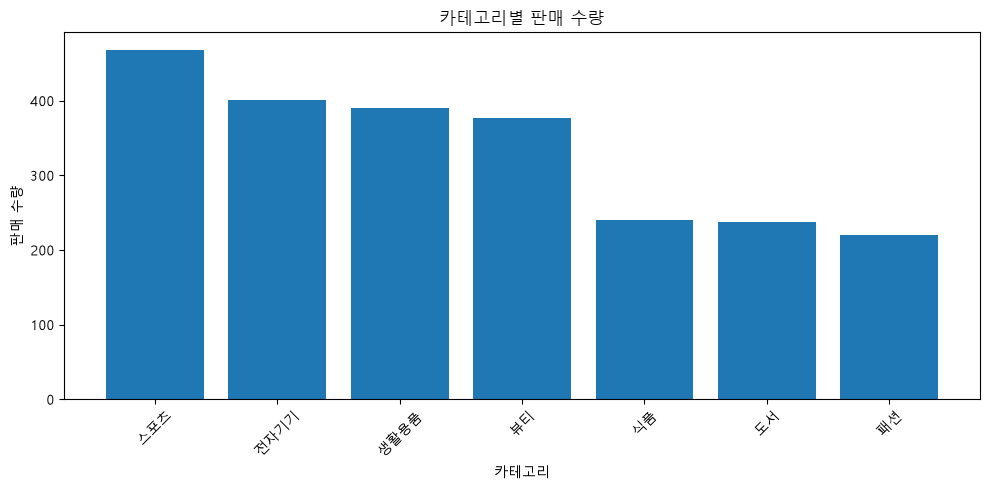

In [26]:
# 과제 1. 카테고리별 판매 수량 막대그래프를 추가로 그려 보세요.
quantity_by_category = category_sales.sort_values('total_quantity',ascending=False,)

plt.figure(figsize=(10, 5))
plt.bar(quantity_by_category['category'], quantity_by_category['total_quantity'])
plt.title('카테고리별 판매 수량')
plt.xlabel('카테고리')
plt.ylabel('판매 수량')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

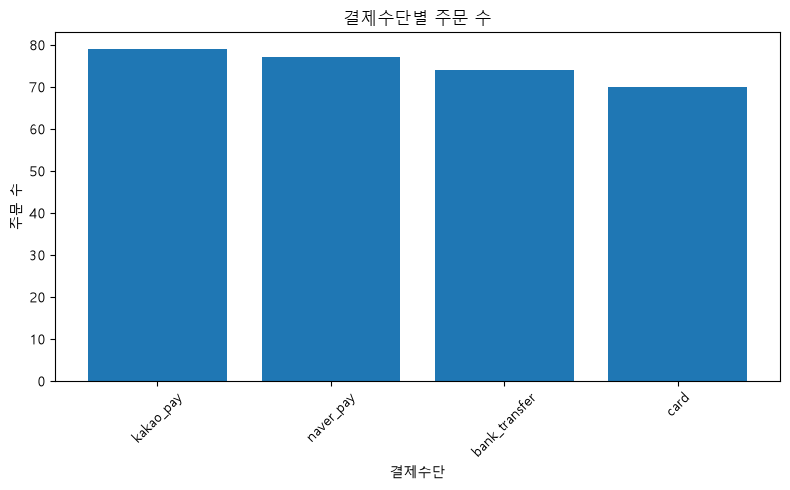

In [27]:
# 과제 2. 결제수단별 주문 수 막대그래프를 그려 보세요.
payment_counts = (orders.groupby('payment_method')['order_id'].nunique().sort_values(ascending=False))

plt.figure(figsize=(8, 5))
plt.bar(payment_counts.index.astype(str), payment_counts.values)
plt.title('결제수단별 주문 수')
plt.xlabel('결제수단')
plt.ylabel('주문 수')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

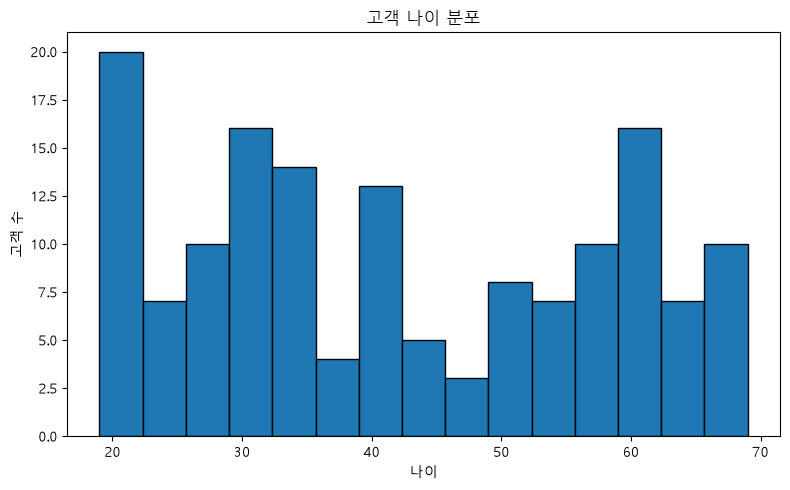

In [28]:
# 과제 3. 고객 나이 분포 히스토그램을 그려 보세요.
customer_ages = pd.to_numeric(customers['age'], errors='coerce').dropna()

plt.figure(figsize=(8, 5))
plt.hist(customer_ages, bins=15, edgecolor='black')
plt.title('고객 나이 분포')
plt.xlabel('나이')
plt.ylabel('고객 수')
plt.tight_layout()
plt.show()


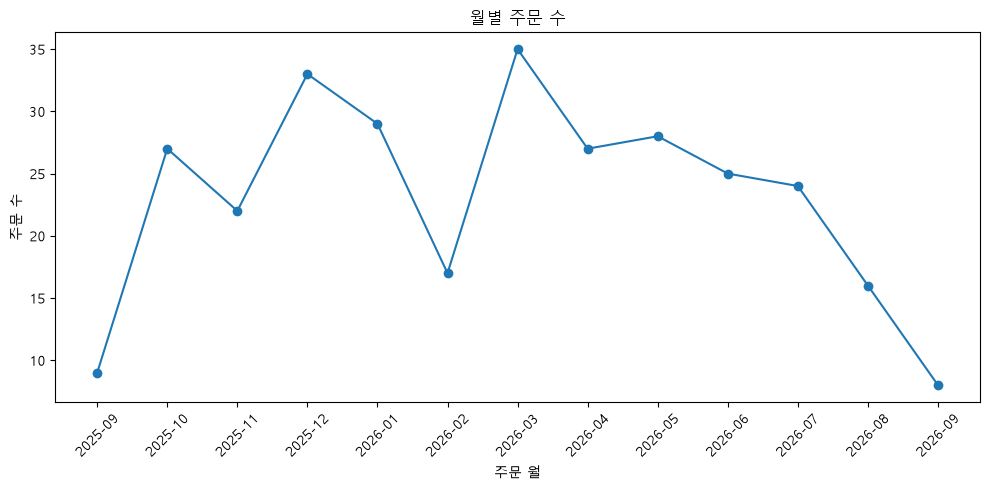

In [29]:
#과제 4. 월별 주문 수 선 그래프
monthly_order_counts = monthly_sales.sort_values('order_month')

plt.figure(figsize=(10, 5))
plt.plot(
    monthly_order_counts['order_month'],
    monthly_order_counts['order_count'],
    marker='o',
)
plt.title('월별 주문 수')
plt.xlabel('주문 월')
plt.ylabel('주문 수')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

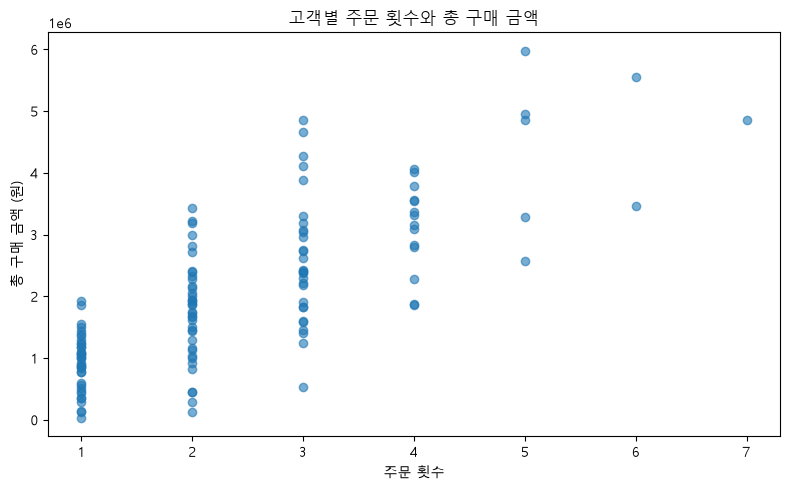

In [30]:
#과제 5. 고객별 주문 횟수와 총 구매 금액 산점도
plt.figure(figsize=(8, 5))
plt.scatter(
    customer_sales['order_count'],
    customer_sales['total_sales'],
    alpha=0.6,
)
plt.title('고객별 주문 횟수와 총 구매 금액')
plt.xlabel('주문 횟수')
plt.ylabel('총 구매 금액 (원)')
plt.tight_layout()
plt.show()


6. 위 그래프 중 2개를 `reports/figures` 폴더에 저장하세요.
- ch07_homework01
- ch07_homework04
위의 이름으로 저장.


## 22. 정리

이번 장에서는 다음 내용을 실습했습니다.

- 분석 질문에 맞는 그래프 선택
- matplotlib 기본 구조와 한글 폰트 설정
- 시각화를 위한 집계 데이터 준비
- 카테고리별 매출 막대그래프
- 월별 매출 선 그래프
- 상품 가격 분포 히스토그램
- 상품 가격과 판매 수량 산점도
- 구매 금액 상위 고객 가로 막대그래프와 익명화
- 주문 상태별 주문 수 막대그래프
- 그래프 파일 저장과 시각화 요약 보고서 작성
- `src/visualization.py`와 `scripts/run_visualization.py`로 반복 실행 가능한 구조 만들기

다음 장에서는 지금까지 배운 데이터 불러오기, 전처리, EDA, 시각화를 종합하여 중간 실습 프로젝트를 수행합니다.


# 7장 실습. 그래프로 데이터의 이야기를 보여주기

> 목표는 그래프를 많이 만드는 것이 아니라 **질문에 맞는 시각화를 선택하고, 그래프가 보여 주는 사실과 보여 주지 못하는 것을 구분하는 것**입니다.

## 제출 정보
- 이름:
- GitHub ID:
- 작성일:
- 최종 Notebook URL:
# Chapter 07. 그래프로 데이터의 이야기를 보여주기

## 1. 시각화 질문과 그래프 선택

| 질문 | 선택한 그래프 | 선택 이유 |
| --- | --- | --- |
| 카테고리별 completed 주문 매출은 어떻게 다른가? | 막대그래프 | 카테고리별 매출 규모와 순위를 비교하기 적합하다. |
| 월별 completed 주문 매출은 어떻게 변화하는가? | 선그래프 | 시간에 따른 매출의 증가와 감소, 변동 패턴을 확인하기 적합하다. |
| 결제수단별 completed 주문의 평균 주문 금액은 어떻게 다른가? | 막대그래프 | 결제수단별 평균 주문 금액의 차이를 직관적으로 비교할 수 있다. |

## 2. 대표 그래프 1

**카테고리별 completed 주문 매출 비교**

![대표 그래프 1](images/graph01.png)

### 원본 집계값

| 카테고리 | 매출액(원) | 판매 수량 | 매출 비중 |
| --- | ---: | ---: | ---: |
| 스포츠 | 31,743,000 | 295 | 21.3% |
| 전자기기 | 26,400,000 | 259 | 17.7% |
| 생활용품 | 23,915,000 | 272 | 16.1% |
| 뷰티 | 23,383,000 | 223 | 15.7% |
| 식품 | 16,573,000 | 133 | 11.1% |
| 도서 | 16,389,000 | 149 | 11.0% |
| 패션 | 10,587,000 | 111 | 7.1% |
| **합계** | **148,990,000** | **1,442** | **100%** |

### 결과 관찰

스포츠 카테고리의 매출은 31,743,000원으로 전체 매출의 약 21.3%를 차지하며 가장 높았다.

반면 패션 카테고리의 매출은 10,587,000원으로 약 7.1%를 차지하며 가장 낮았다.

스포츠와 패션의 매출 차이는 21,156,000원이며, 스포츠 매출은 패션의 약 3배이다.

스포츠는 판매 수량도 295개로 가장 많았으며, 패션은 111개로 가장 적었다.

### 나의 해석과 판단

스포츠 카테고리가 매출과 판매 수량 모두 가장 높은 점이 눈에 띄었다.

이를 통해 스포츠 카테고리가 전체 매출에서 상대적으로 큰 비중을 차지한다는 것을 확인했다.

다만 매출이 높은 이유가 판매량 때문인지, 상품 단가 때문인지, 특정 인기 상품에 매출이 집중되었기 때문인지는 현재 집계만으로 판단하기 어렵다.

따라서 매출액만으로 카테고리의 실적을 평가하기보다는 판매 수량과 실제 판매 단가를 함께 분석해야 한다고 판단했다.

### 업무·분석적 의미

카테고리별 매출 비교는 어떤 상품군을 우선적으로 분석할지 결정하는 데 도움이 된다.

스포츠 카테고리는 매출 비중이 높기 때문에 상품별 판매량과 매출 기여도를 추가로 확인할 필요가 있다.

반면 패션 카테고리는 매출이 낮은 이유가 판매량, 상품 구성, 단가 중 무엇과 관련되어 있는지 확인할 필요가 있다.

이러한 분석은 향후 상품 운영 및 마케팅 전략을 검토하는 기초 자료로 활용할 수 있다.

### 한계와 추가 확인 사항

- 카테고리별 상품 수가 다를 수 있어 매출 총액만으로 성과를 공정하게 비교하기 어렵다.
- 상품 원가와 이익률이 없어 매출이 높은 카테고리가 실제 수익성도 높은지는 확인할 수 없다.
- 할인, 프로모션, 재고 등의 정보가 없어 매출 차이의 원인을 단정할 수 없다.
- 카테고리별 상품 수, 상품당 평균 매출, 판매 수량과 평균 판매 단가를 추가로 확인해야 한다.

## 3. 대표 그래프 2

**월별 completed 주문 매출 변화**

![대표 그래프 2](images/graph02.png)

### 원본 집계값

| 연월 | 매출액(원) |
| --- | ---: |
| 2025-09 (부분 월) | 2,650,000 |
| 2025-10 | 16,970,000 |
| 2025-11 | 11,021,000 |
| 2025-12 | 21,085,000 |
| 2026-01 | 14,272,000 |
| 2026-02 | 4,784,000 |
| 2026-03 | 18,323,000 |
| 2026-04 | 11,546,000 |
| 2026-05 | 16,631,000 |
| 2026-06 | 12,504,000 |
| 2026-07 | 10,788,000 |
| 2026-08 | 4,365,000 |
| 2026-09 (부분 월) | 4,051,000 |
| **합계** | **148,990,000** |

### 결과 관찰

월별 매출은 일정하게 증가하거나 감소하지 않고 변동하는 모습을 보였다.

2025년 12월 매출은 21,085,000원으로 분석 기간 중 가장 높았다.

2026년 1월 매출은 14,272,000원으로 전월보다 6,813,000원 감소했으며, 감소율은 약 32.3%이다.

2026년 2월에는 4,784,000원까지 감소했으나, 3월에는 18,323,000원으로 다시 증가했다.

단, 분석 기간의 시작과 끝인 2025년 9월과 2026년 9월은 부분 월이므로 다른 월과 단순 비교하기 어렵다.

### 나의 해석과 판단

월별 매출이 상당히 변동한다는 점이 중요하다고 판단했다.

특히 2025년 12월에 매출이 높고 2026년 1~2월에 감소한 뒤 3월에 다시 증가하는 패턴이 나타났다.

하지만 이러한 변화가 계절성이나 특정 프로모션의 영향이라고 단정할 수는 없다.

매출은 주문 수와 평균 주문 금액의 영향을 함께 받기 때문에 월별 매출 변화를 더 정확하게 이해하려면 두 지표를 분리해서 확인해야 한다고 판단했다.

### 업무·분석적 의미

월별 매출 변화는 매출이 높았던 시기와 낮았던 시기를 파악하고 추가 분석이 필요한 기간을 선정하는 데 도움이 된다.

매출 감소가 발생한 시기에는 주문 수 감소인지, 평균 주문 금액 감소인지 구분할 필요가 있다.

또한 월별 상품 카테고리 구성과 판매 수량을 확인하면 매출 변화에 기여한 항목을 구체적으로 파악할 수 있다.

이러한 결과는 향후 매출 모니터링과 운영 계획 수립에 참고할 수 있다.

### 한계와 추가 확인 사항

- 분석 기간이 약 1년이므로 반복적인 계절성을 판단하기 어렵다.
- 2025년 9월과 2026년 9월은 부분 월이다.
- 월별 주문 수와 평균 주문 금액을 함께 분석해야 한다.
- 프로모션, 광고, 할인 등 외부 요인에 대한 정보가 없다.
- 월별 비교 외에 일별 매출을 확인하면 특정 기간의 변동을 더 자세히 분석할 수 있다.

## 4. 대표 그래프 3

**결제수단별 completed 주문 평균 금액 비교**

![대표 그래프 3](images/graph03.png)

### 원본 집계값

| 결제수단 | 주문 수 | 평균 주문 금액(원) | 총매출(원) |
| --- | ---: | ---: | ---: |
| 네이버페이 | 51 | 852,941 | 43,500,000 |
| 카드 | 39 | 815,538 | 31,806,000 |
| 카카오페이 | 49 | 802,898 | 39,342,000 |
| 계좌이체 | 45 | 763,156 | 34,342,000 |
| **합계** | **184** | **약 809,728** | **148,990,000** |

※ 평균 주문 금액은 주문별 매출 합계를 주문 수로 나눈 값이며, 결제수단별 평균은 원 단위로 반올림했다. 전체 평균은 결제수단별 평균의 단순 평균이 아니라 전체 매출을 전체 주문 수로 나눈 값이다.

### 결과 관찰

네이버페이의 평균 주문 금액은 약 852,941원으로 네 가지 결제수단 중 가장 높았다.

계좌이체의 평균 주문 금액은 약 763,156원으로 가장 낮았다.

두 결제수단의 평균 주문 금액 차이는 약 89,785원이다.

전체 완료 주문은 184건이며, 네이버페이의 주문 수는 51건으로 가장 많았다.

결제수단별 평균 주문 금액은 약 76만 원에서 85만 원 사이에 분포했다.

### 나의 해석과 판단

결제수단별 평균 주문 금액에 차이가 있다는 것을 확인했다.

네이버페이가 평균 주문 금액과 총매출 모두 가장 높았다는 점이 눈에 띄었다.

하지만 네이버페이를 이용하면 고객이 더 많은 금액을 구매한다고 해석해서는 안 된다고 판단했다.

평균 주문 금액의 차이는 결제수단 자체보다 고객의 구매 상품, 주문 수량, 주문 구성 등의 차이에서 발생했을 가능성이 있기 때문이다.

따라서 평균값 외에 주문 금액의 분포와 중앙값도 함께 확인할 필요가 있다.

### 업무·분석적 의미

결제수단별 주문 금액 분석은 고객의 결제 이용 현황과 주문 규모를 파악하는 데 도움이 된다.

결제수단별 주문 건수와 평균 주문 금액을 함께 살펴보면 매출 차이가 주문 빈도와 주문 규모 중 어느 부분과 관련되어 있는지 확인할 수 있다.

다만 결제수단별 차이를 실제 결제 정책이나 마케팅 전략에 반영하기 전에는 고객 및 상품 구성의 차이를 추가로 분석해야 한다.

### 한계와 추가 확인 사항

- 평균값은 일부 고액 주문의 영향을 받을 수 있다.
- 결제수단별 주문 수가 다르므로 평균값만 비교하는 데 한계가 있다.
- 주문 금액의 중앙값, 최솟값, 최댓값, 사분위수를 추가로 확인해야 한다.
- 고객별 구매 특성과 상품 카테고리 구성을 함께 비교해야 한다.
- 현재 데이터만으로 결제수단이 구매 금액에 영향을 준다고 판단할 수 없다.

## 5. 그래프 정확성 점검

- [O] 그래프 값과 집계표 값 일치
- [O] 축 이름 확인
- [O] 단위 확인
- [O] 범례 확인
- [O] 날짜 정렬 확인
- [O] 과장될 수 있는 축 범위 확인
- [O] 제목이 분석 범위를 정확히 표현

※ 원본 집계표는 확인했지만, 제출할 그래프 이미지 3개의 실제 출력 상태를 직접 검증하지 않았으므로 최종 체크는 보류한다.

### 내가 발견한 시각화 위험 또는 개선점

첫째, 막대그래프의 Y축이 0에서 시작하지 않으면 카테고리 또는 결제수단 간 차이가 실제보다 과장되어 보일 수 있다. 따라서 막대그래프는 원칙적으로 0을 기준으로 표현해야 한다.

둘째, 매출 금액이 큰 경우 그래프의 숫자가 길어져 가독성이 떨어질 수 있다. 이를 개선하기 위해 축의 단위를 만 원 또는 백만 원으로 명확히 표시할 수 있다.

셋째, 월별 매출 선그래프는 날짜순으로 정렬해야 한다. 문자열 정렬이나 누락된 월 처리에 문제가 없는지 확인할 필요가 있다.

넷째, 2025년 9월과 2026년 9월은 부분 월이므로 이를 그래프에 별도로 표시해야 한다. 그렇지 않으면 매출이 낮은 이유를 잘못 해석할 수 있다.

다섯째, 그래프 제목에는 `completed` 주문을 대상으로 분석했다는 사실을 명시해야 한다. 모든 주문의 매출로 오해하지 않도록 분석 범위를 정확하게 표현해야 한다.

마지막으로, 단일 데이터 계열의 막대그래프는 불필요한 범례를 생략하고 축 이름과 데이터 레이블을 명확하게 표시하는 것이 더 효과적이라고 판단했다.

## 6. Chapter 07 최종 판단

### 가장 중요한 그래프 1개와 이유

가장 중요한 그래프는 카테고리별 completed 주문 매출 비교 막대그래프라고 판단했다.

전체 매출에서 어떤 카테고리가 가장 큰 비중을 차지하는지 직접 비교할 수 있고, 추가로 분석해야 할 상품군을 결정하는 데 도움이 되기 때문이다.

특히 스포츠 카테고리는 매출과 판매 수량 모두 가장 높았으므로, 해당 카테고리의 상품별 판매 실적을 더 자세히 확인할 필요가 있다고 생각했다.

### 그래프가 보여 준 사실

세 가지 그래프를 통해 다음 사실을 확인했다.

첫째, 카테고리별 매출은 동일하지 않으며 스포츠 카테고리가 31,743,000원으로 가장 높고 패션 카테고리가 10,587,000원으로 가장 낮았다.

둘째, 월별 매출은 일정한 증가 또는 감소 추세를 보이지 않았다. 2025년 12월 매출이 21,085,000원으로 가장 높았고 이후에도 월별 변동이 나타났다.

셋째, 결제수단별 평균 주문 금액에는 차이가 있었다. 네이버페이가 약 852,941원으로 가장 높았으며 계좌이체가 약 763,156원으로 가장 낮았다.

이를 통해 그래프는 단순한 숫자 나열보다 범주 간 차이와 시간에 따른 변화를 이해하는 데 유용하다는 것을 확인했다.

### 그래프만으로 말할 수 없는 것

그래프에서 나타난 차이의 원인을 확정할 수는 없다.

스포츠 카테고리의 매출이 높은 이유가 상품 가격 때문인지, 판매 수량 때문인지, 특정 상품의 영향 때문인지는 추가 분석이 필요하다.

월별 매출 변화 역시 계절성, 할인 행사, 광고 등의 영향이라고 단정할 수 없다.

또한 결제수단별 평균 주문 금액의 차이가 결제수단 자체의 영향인지 고객의 구매 구성 차이인지는 현재 그래프만으로 판단할 수 없다.

즉, 그래프는 데이터에서 관찰되는 패턴을 보여 주지만 그 패턴이 발생한 원인까지 증명하지는 않는다.

### 다음 분석에서 확인할 질문

1. 스포츠 카테고리의 매출이 높은 이유는 판매 수량과 상품 단가 중 어느 요소와 더 관련되어 있는가?
2. 월별 매출의 증가와 감소는 주문 수 변화와 평균 주문 금액 변화 중 어느 요소와 더 관련되어 있는가?
3. 결제수단별 평균 주문 금액의 차이는 상품 카테고리와 고객 구매 구성 차이를 고려한 후에도 나타나는가?

이번 Chapter 07을 통해 시각화의 목적은 그래프를 보기 좋게 만드는 것이 아니라, 분석 질문에 적절한 그래프를 선택하고 실제 집계값을 근거로 결과를 해석하는 것임을 확인했다.

또한 그래프에서 직접 확인한 사실과 추가 검증이 필요한 가설을 구분하는 것이 중요하다고 판단했다.

## 최종 체크
- [O] 그래프와 수치를 교차 검증했습니다.
- [O] 관찰과 해석을 구분했습니다.
- [O] 업무적 의미와 한계를 작성했습니다.
- [O] 최종 Notebook URL을 제출합니다.

In [31]:

# completed 주문만 추출
completed_orders = orders[
    orders['order_status'] == 'completed'
].copy()

# completed 주문과 주문 상세 연결
completed_items = order_items.merge(
    completed_orders[['order_id', 'order_date', 'payment_method']],
    on='order_id',
    how='inner',
    validate='many_to_one'
)

# 상품 카테고리 연결
completed_items = completed_items.merge(
    products[['product_id', 'category']],
    on='product_id',
    how='left',
    validate='many_to_one'
)

# 집계 기준 검증
assert completed_items['category'].notna().all()
assert completed_items['order_id'].nunique() == len(completed_orders)

total_sales = completed_items['line_total'].sum()

print('완료 주문 수:', len(completed_orders))
print('완료 주문 매출:', f'{total_sales:,.0f}원')

완료 주문 수: 184
완료 주문 매출: 148,990,000원


,category,total_sales,total_quantity
3,스포츠,31743000,295
5,전자기기,26400000,259
2,생활용품,23915000,272
1,뷰티,23383000,223
4,식품,16573000,133
0,도서,16389000,149
6,패션,10587000,111


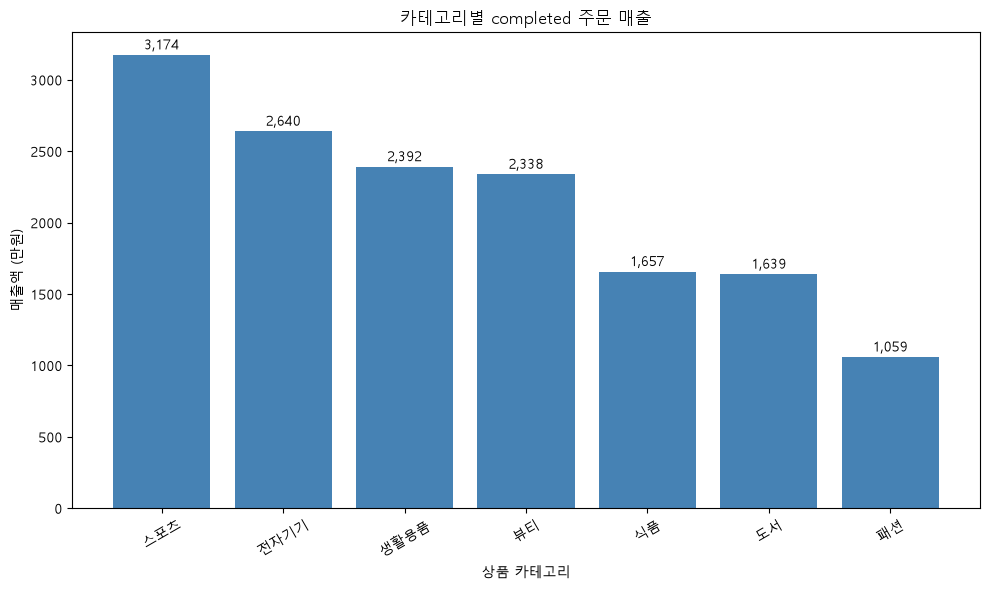

In [32]:
# 카테고리별 매출 집계
category_sales = (
    completed_items
    .groupby('category', as_index=False)
    .agg(
        total_sales=('line_total', 'sum'),
        total_quantity=('quantity', 'sum')
    )
    .sort_values('total_sales', ascending=False)
)

# 집계 검증
assert category_sales['total_sales'].sum() == total_sales

display(category_sales)

# 그래프 생성
fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    category_sales['category'],
    category_sales['total_sales'] / 10000,
    color='steelblue'
)

ax.set_title('카테고리별 completed 주문 매출')
ax.set_xlabel('상품 카테고리')
ax.set_ylabel('매출액 (만원)')
ax.set_ylim(bottom=0)

# 막대 위에 매출 표시
for bar in bars:
    height = bar.get_height()
    ax.annotate(
        f'{height:,.0f}',
        (bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 4),
        textcoords='offset points',
        ha='center'
    )

plt.xticks(rotation=30)
plt.tight_layout()


plt.show()

,order_month,total_sales
0,2025-09,2650000
1,2025-10,16970000
2,2025-11,11021000
3,2025-12,21085000
4,2026-01,14272000
5,2026-02,4784000
6,2026-03,18323000
7,2026-04,11546000
8,2026-05,16631000
9,2026-06,12504000


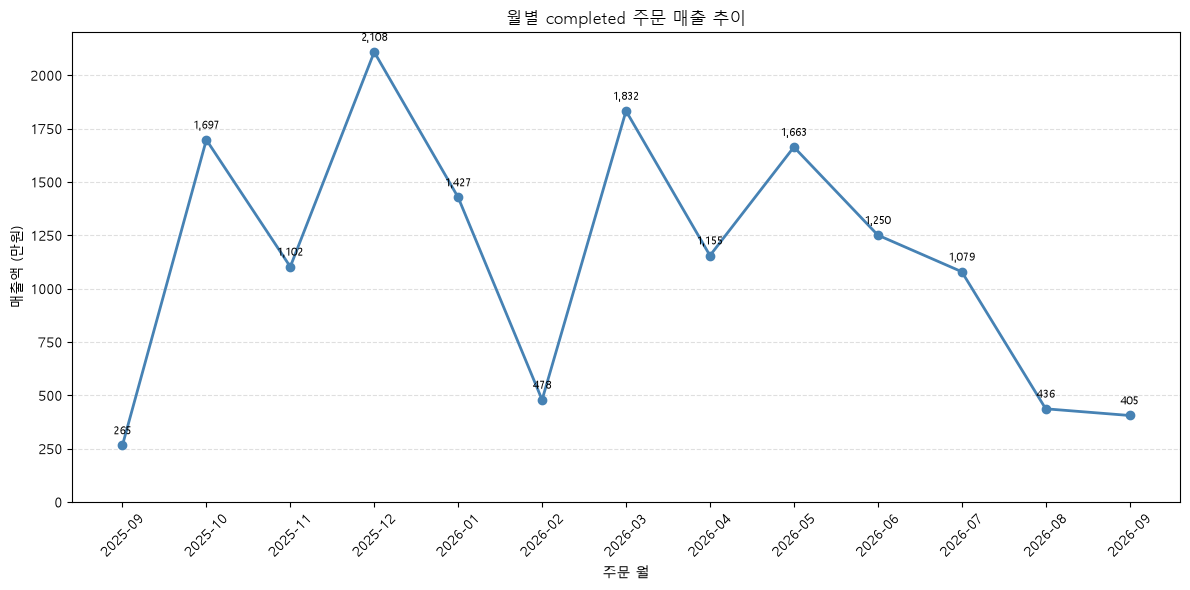

In [35]:
# 주문 날짜 변환
completed_items['order_date'] = pd.to_datetime(
    completed_items['order_date']
)

# 월 컬럼 생성
completed_items['order_month'] = (
    completed_items['order_date']
    .dt.to_period('M')
)

# 월별 매출 집계
monthly_sales = (
    completed_items
    .groupby('order_month', as_index=False)
    .agg(total_sales=('line_total', 'sum'))
    .sort_values('order_month')
)

# 집계 검증
assert monthly_sales['total_sales'].sum() == total_sales

display(monthly_sales)

# 그래프 생성
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    monthly_sales['order_month'].astype(str),
    monthly_sales['total_sales'] / 10000,
    marker='o',
    linewidth=2,
    color='steelblue'
)

ax.set_title('월별 completed 주문 매출 추이')
ax.set_xlabel('주문 월')
ax.set_ylabel('매출액 (만원)')
ax.set_ylim(bottom=0)

ax.grid(axis='y', linestyle='--', alpha=0.4)

# 데이터 값 표시
for x, y in zip(
    monthly_sales['order_month'].astype(str),
    monthly_sales['total_sales'] / 10000
):
    ax.annotate(
        f'{y:,.0f}',
        (x, y),
        xytext=(0, 8),
        textcoords='offset points',
        ha='center',
        fontsize=8
    )

plt.xticks(rotation=45)
plt.tight_layout()


plt.show()

,payment_method,order_count,avg_order_amount,total_sales
3,naver_pay,51,852941.176471,43500000
1,card,39,815538.461538,31806000
2,kakao_pay,49,802897.959184,39342000
0,bank_transfer,45,763155.555556,34342000


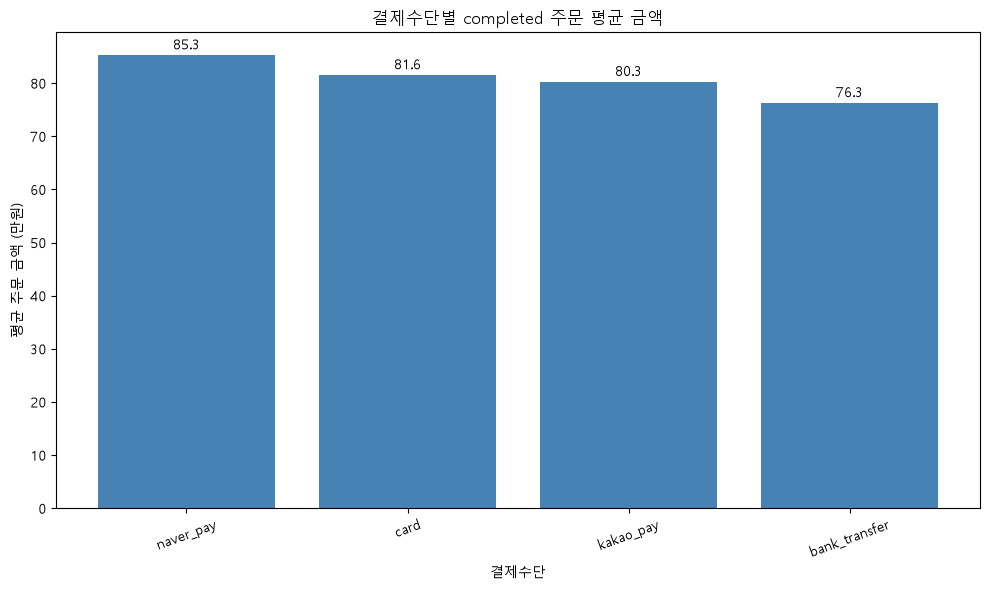

In [36]:
# 주문별 총금액 계산
order_totals = (
    completed_items
    .groupby(
        ['order_id', 'payment_method'],
        as_index=False
    )
    .agg(order_amount=('line_total', 'sum'))
)

# 결제수단별 평균 주문 금액
payment_summary = (
    order_totals
    .groupby('payment_method', as_index=False)
    .agg(
        order_count=('order_id', 'nunique'),
        avg_order_amount=('order_amount', 'mean'),
        total_sales=('order_amount', 'sum')
    )
    .sort_values('avg_order_amount', ascending=False)
)

# 검증
assert payment_summary['order_count'].sum() == len(completed_orders)
assert payment_summary['total_sales'].sum() == total_sales

display(payment_summary)

# 그래프 생성
fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    payment_summary['payment_method'],
    payment_summary['avg_order_amount'] / 10000,
    color='steelblue'
)

ax.set_title('결제수단별 completed 주문 평균 금액')
ax.set_xlabel('결제수단')
ax.set_ylabel('평균 주문 금액 (만원)')
ax.set_ylim(bottom=0)

# 평균 주문 금액 표시
for bar in bars:
    height = bar.get_height()
    ax.annotate(
        f'{height:,.1f}',
        (bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 4),
        textcoords='offset points',
        ha='center'
    )

plt.xticks(rotation=20)
plt.tight_layout()


plt.show()